In [27]:
import xarray as xr
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import verde as vd
import pandas as pd
import seaborn as sns

import sys
sys.path.append("..")

import multipoles as mt
import micromag as mg
from micromag import MICROMETER_TO_METER, TESLA_TO_NANOTESLA

## Overview

This notebook tests the fidelity of spherical harmonics fitting against micromagnetic data used to generate synthetic magnetic field maps.

The evaluation is based on angular and magnetic moment misfits across different particle models and sensor heights.

In [2]:
grid_dir = Path("../..") / "data/micromag_models/tecfiles/grids"
grid_files = sorted(grid_dir.glob("*.nc"))

Processing model: eps12 at height 0.05 µm


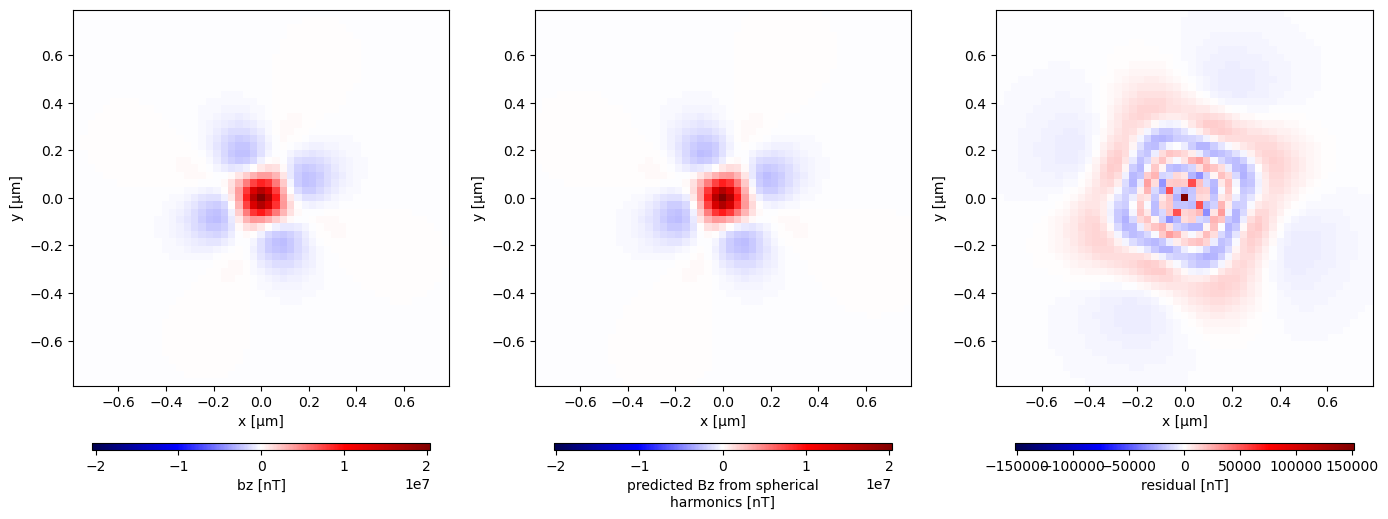

Processing model: eps12 at height 0.075 µm


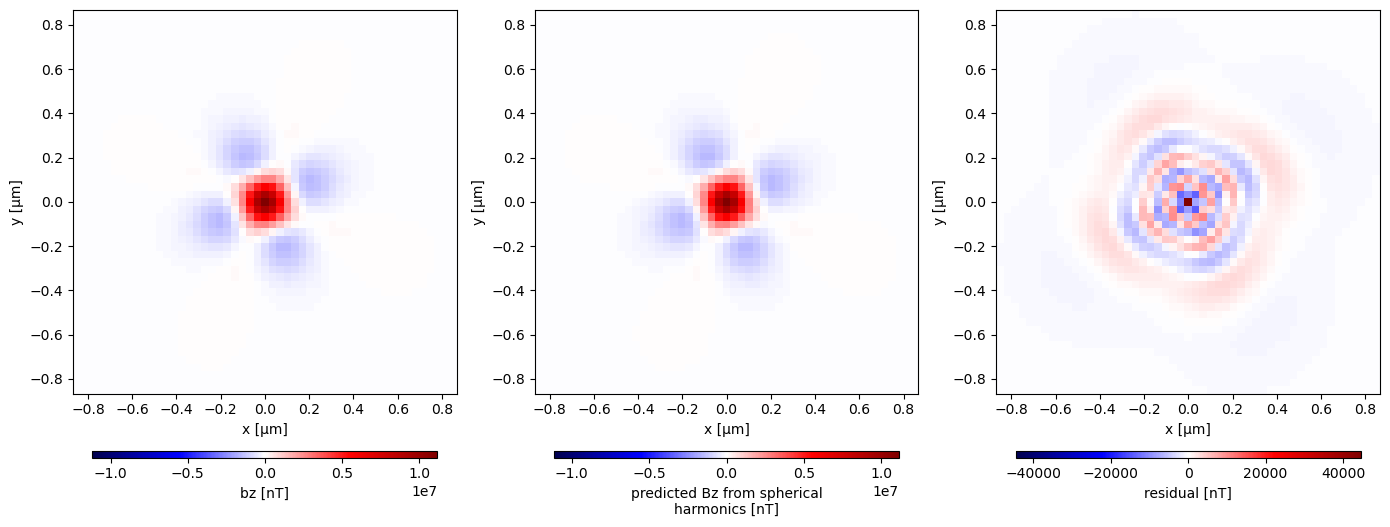

Processing model: eps12 at height 0.1 µm


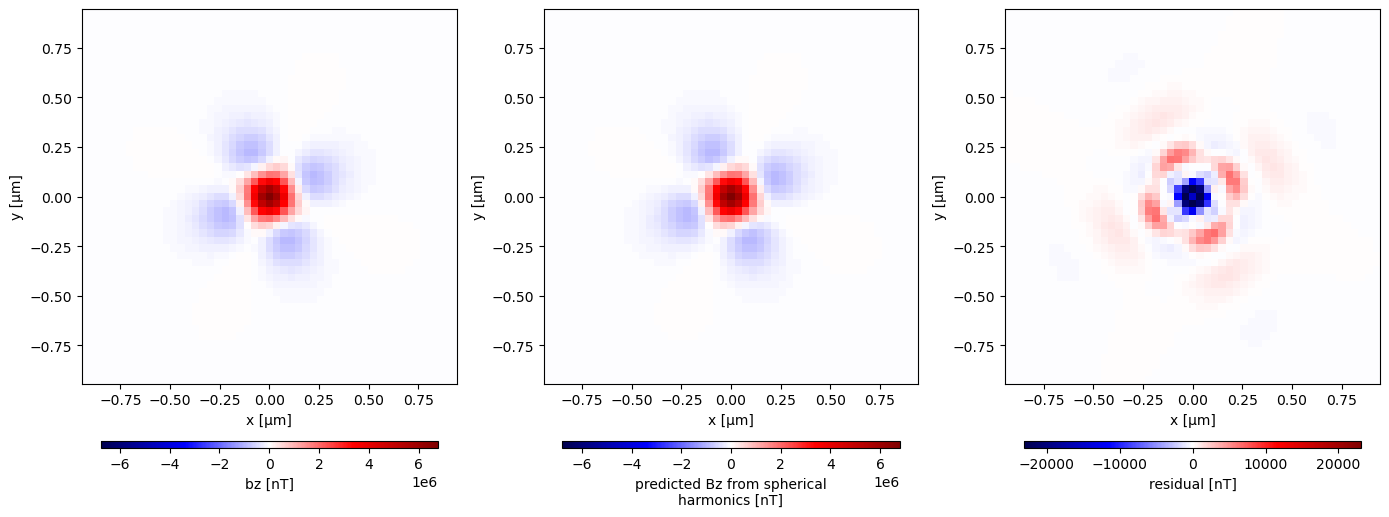

Processing model: eps12 at height 0.15 µm


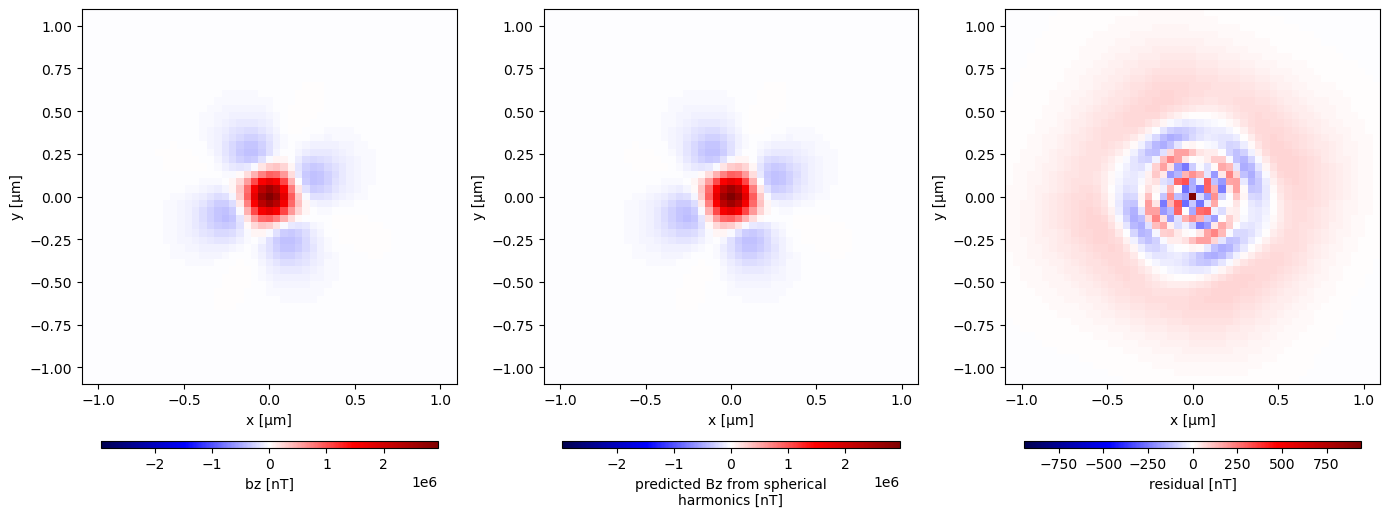

Processing model: eps12 at height 0.2 µm


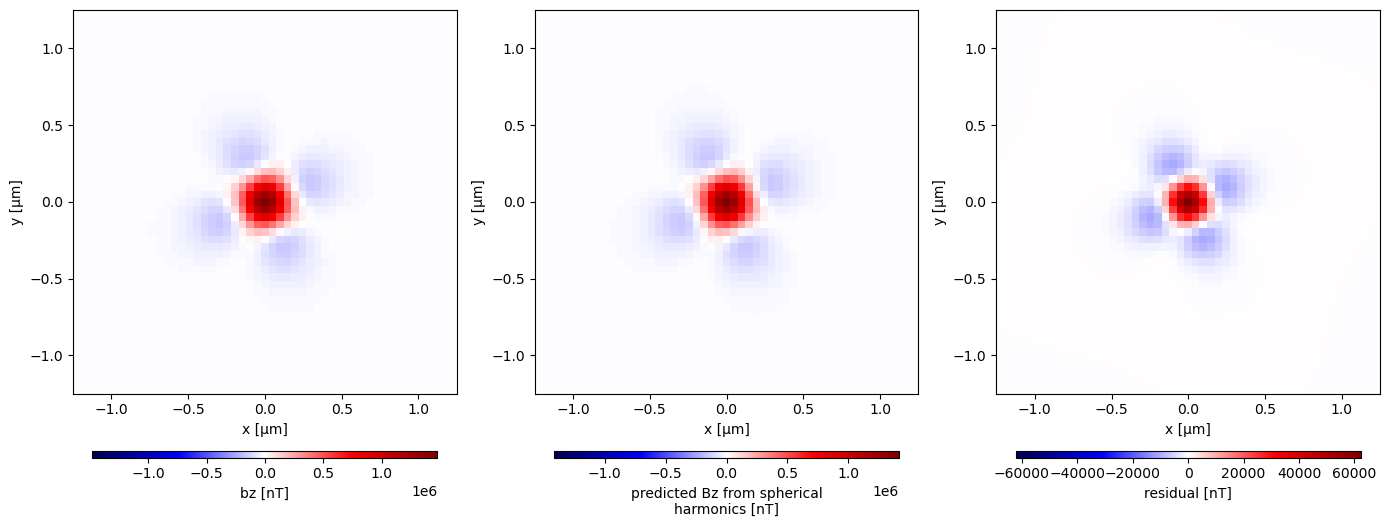

Processing model: eps12 at height 0.25 µm


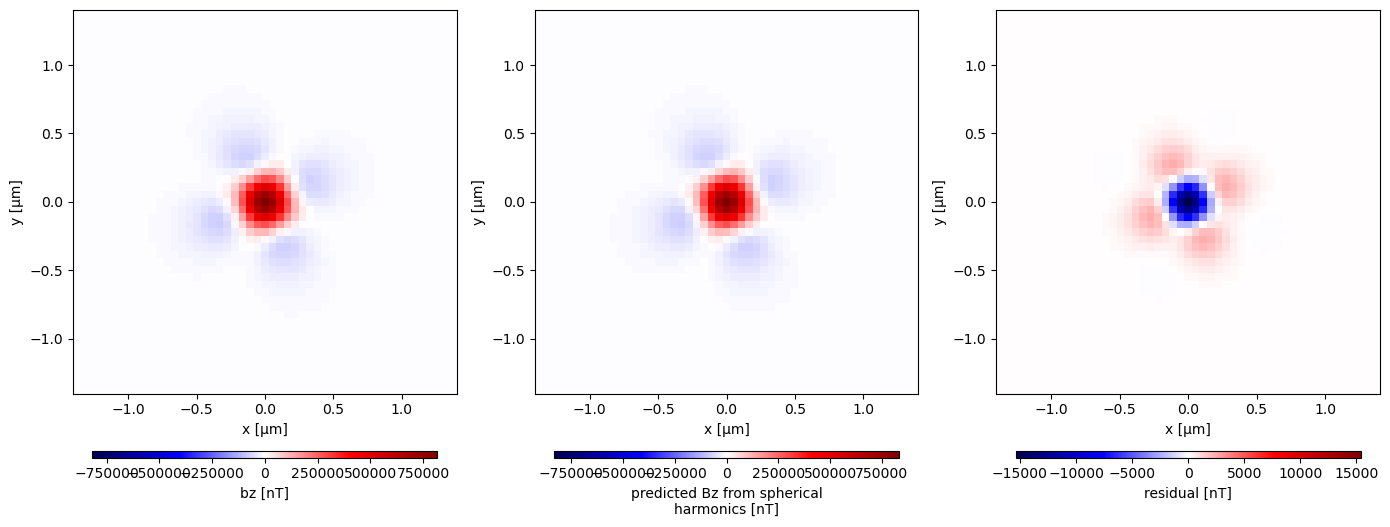

Processing model: eps12 at height 0.35 µm


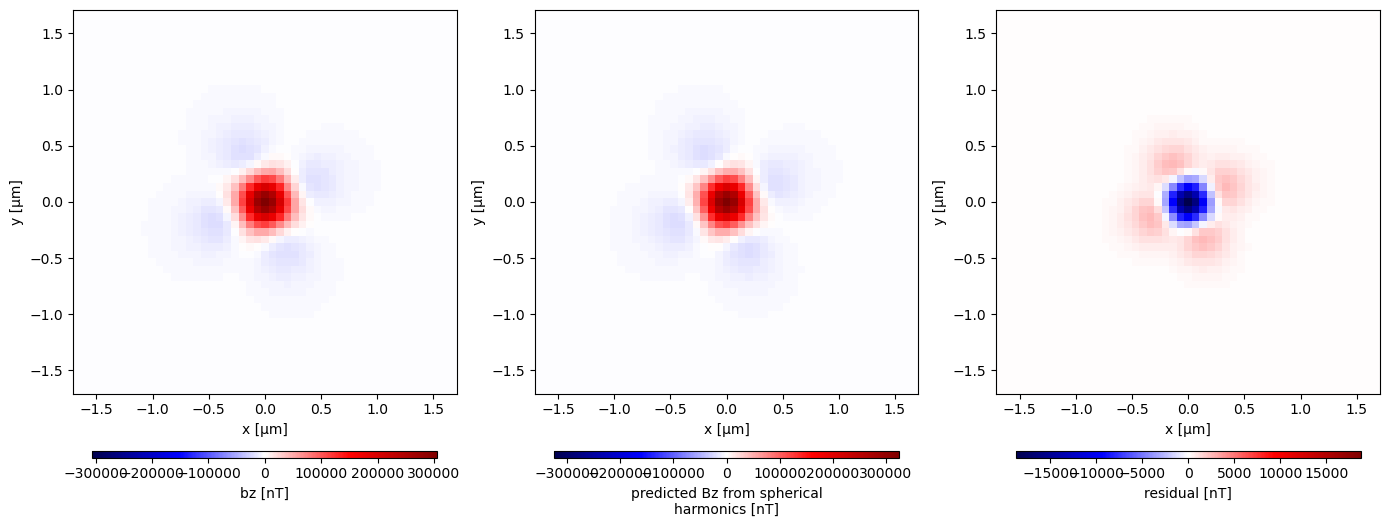

Processing model: eps12 at height 0.5 µm


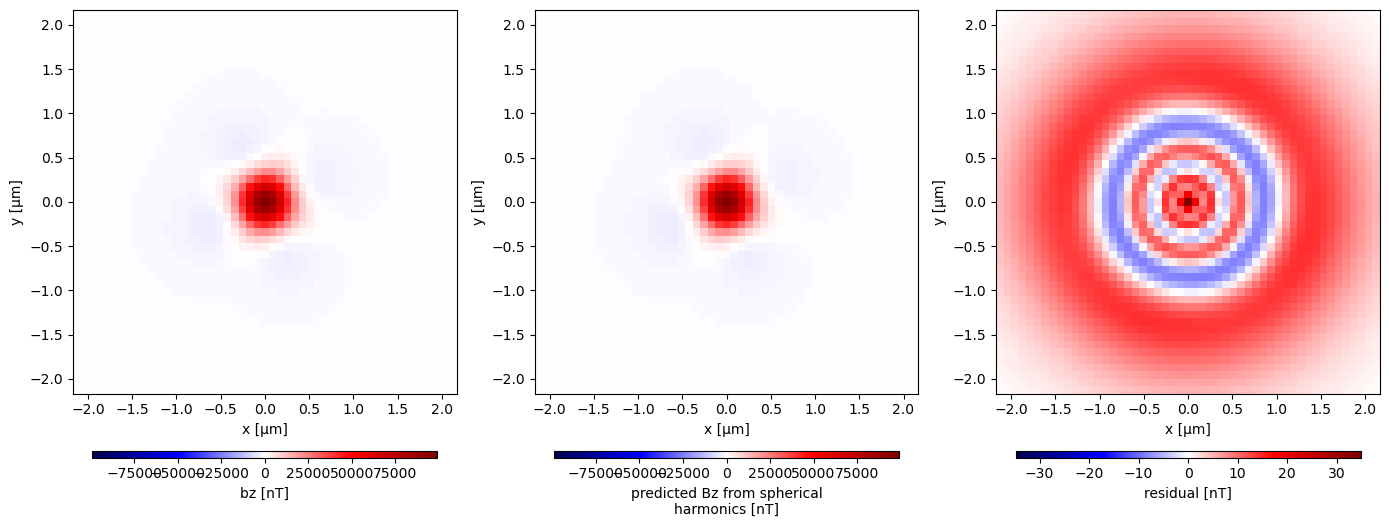

Processing model: eps12 at height 0.75 µm


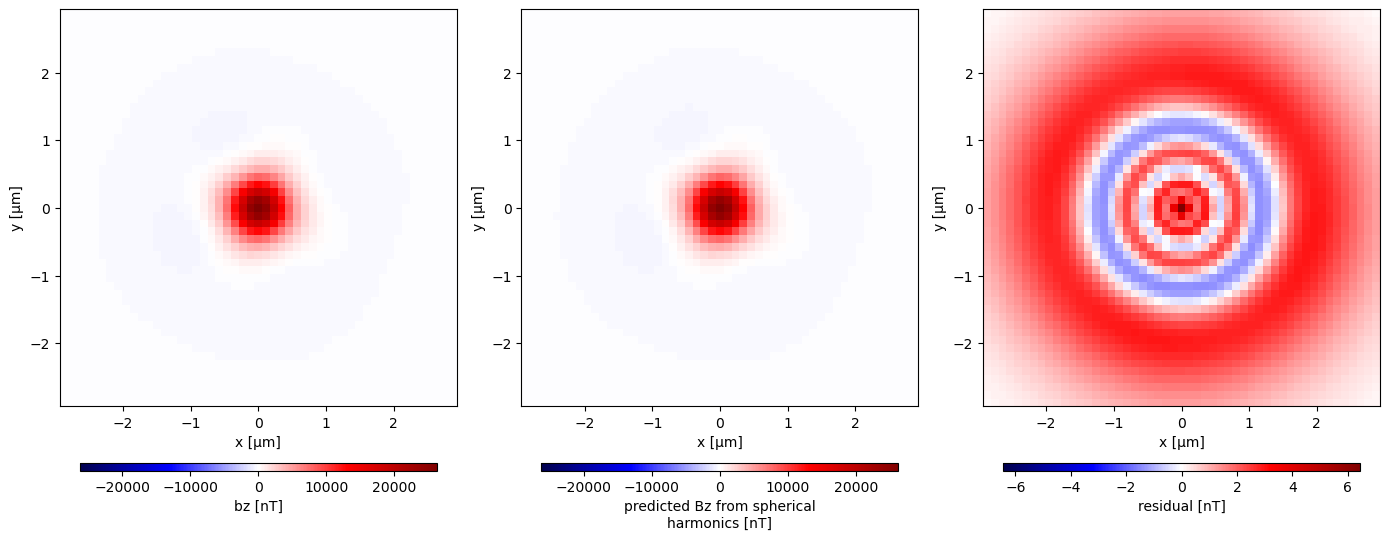

Processing model: eps12 at height 1.0 µm


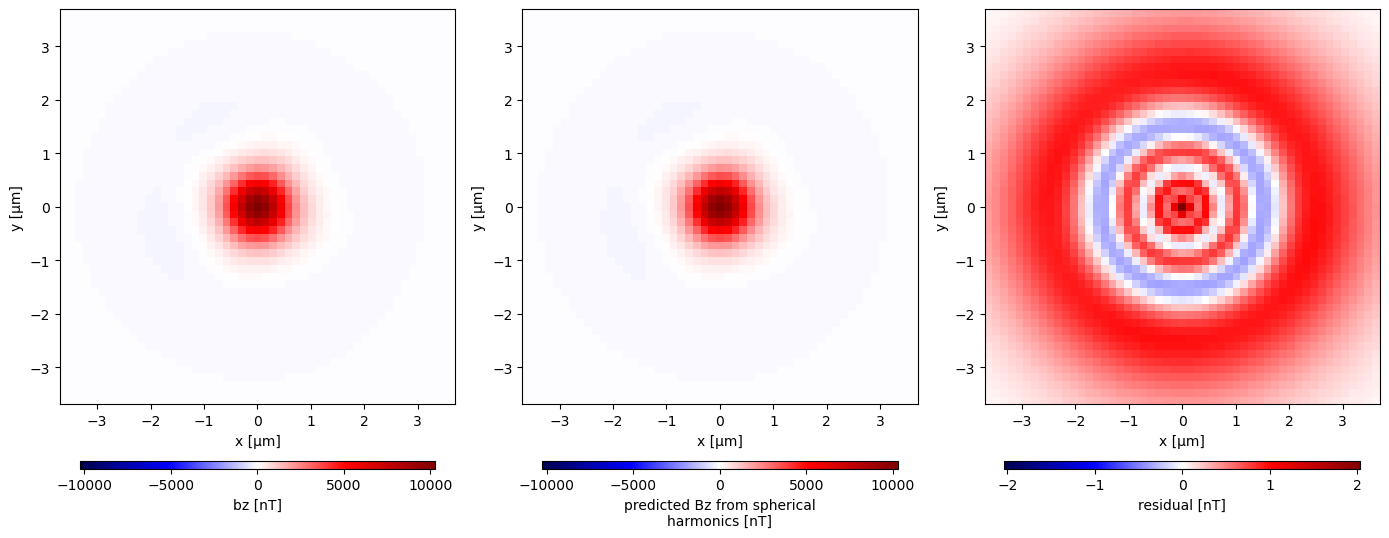

Processing model: eps12 at height 1.25 µm


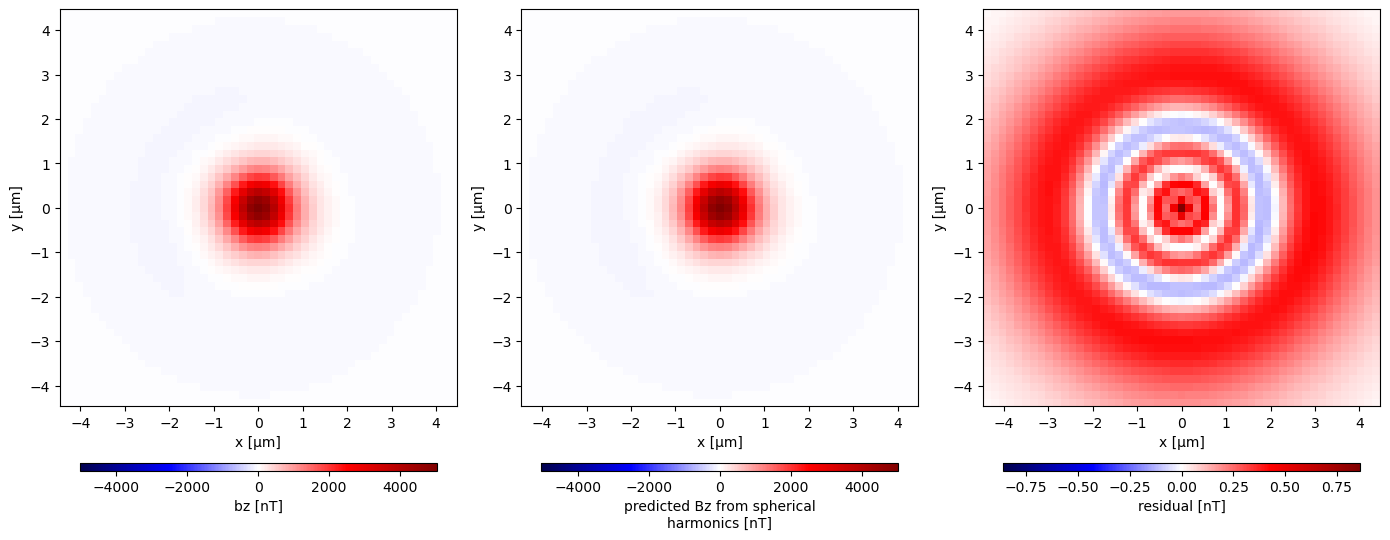

Processing model: eps12 at height 1.5 µm


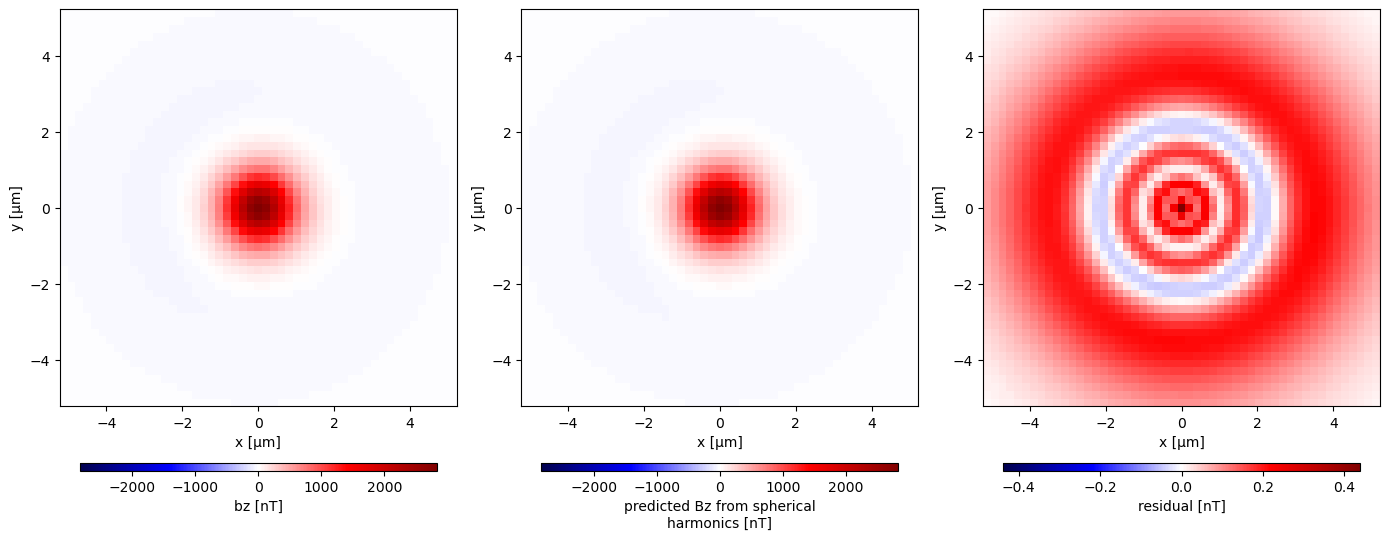

Processing model: eps12 at height 10.0 µm


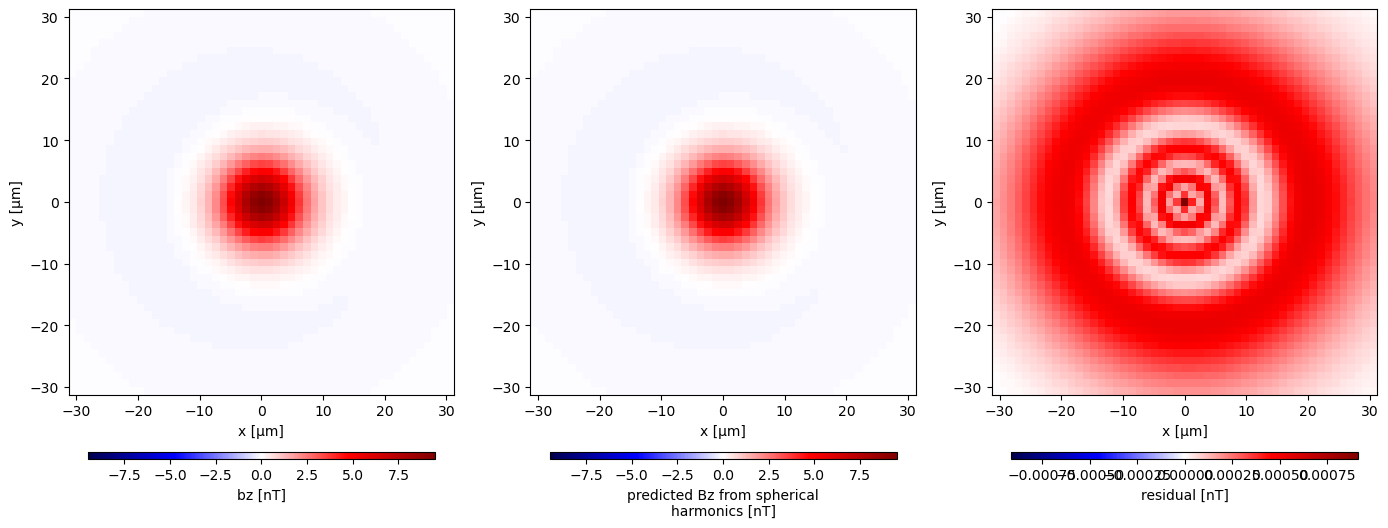

Processing model: eps12 at height 2.0 µm


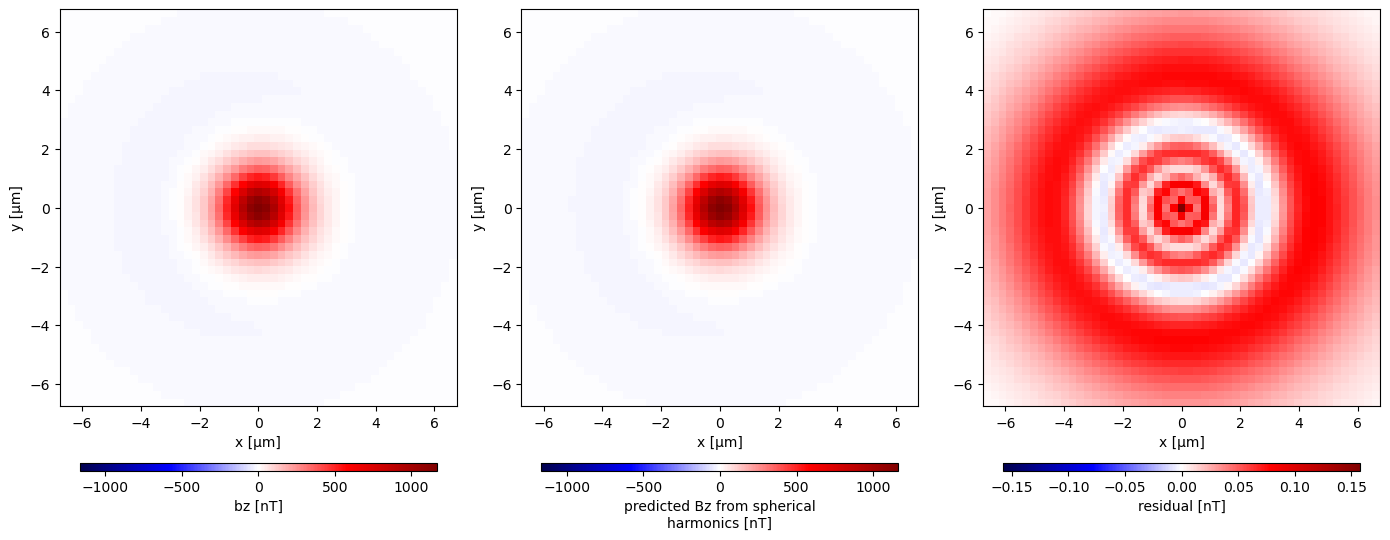

Processing model: eps12 at height 3.0 µm


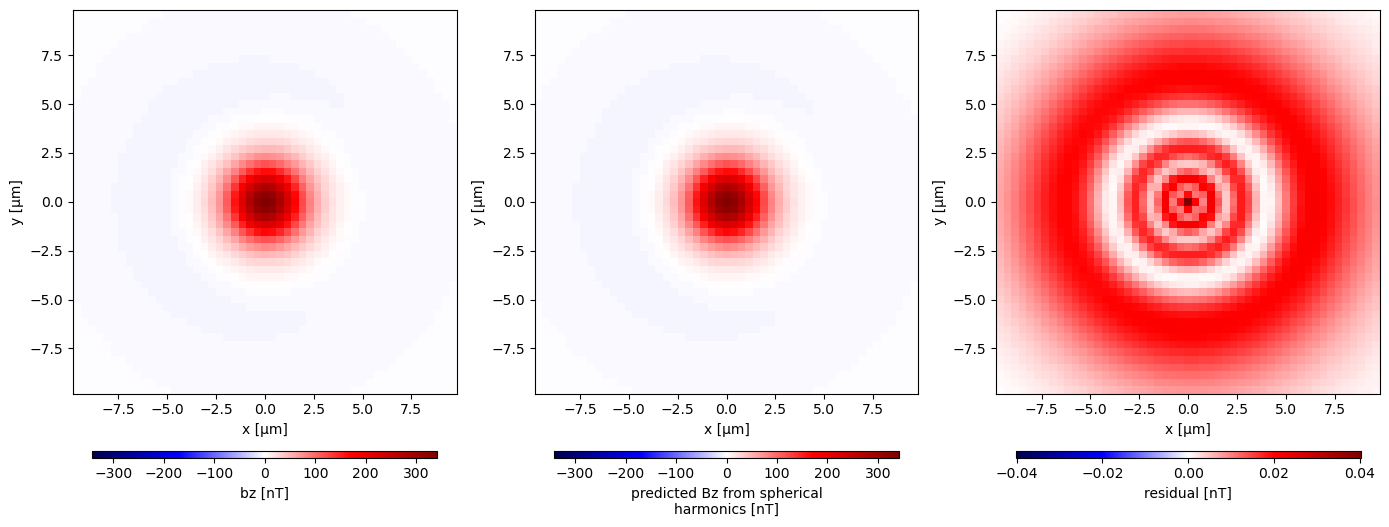

Processing model: eps12 at height 4.0 µm


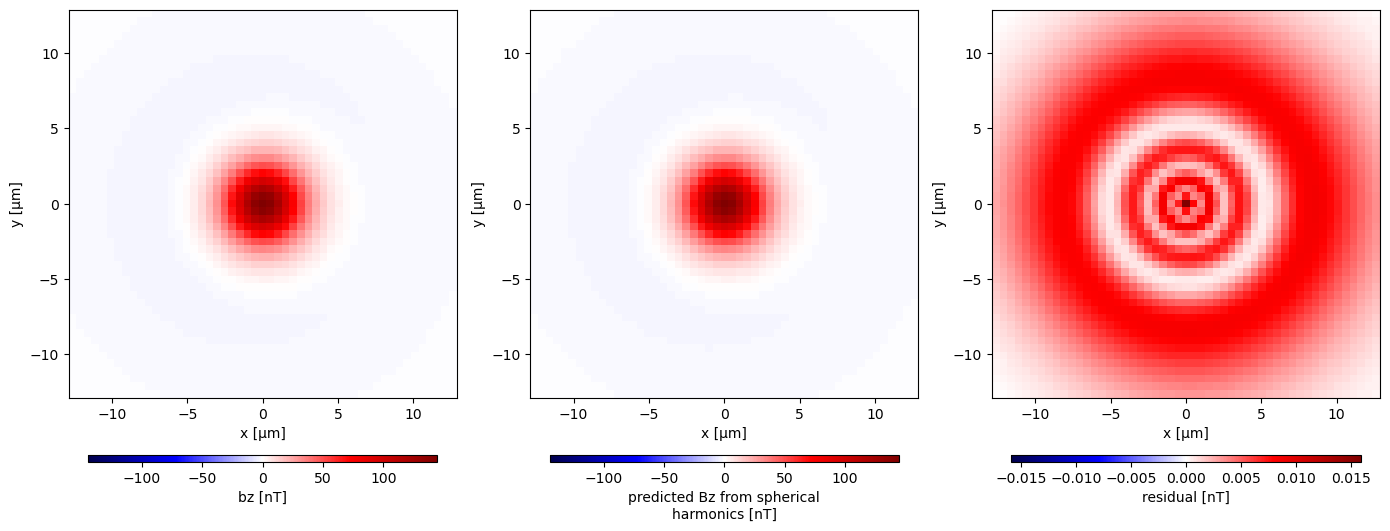

Processing model: eps12 at height 5.0 µm


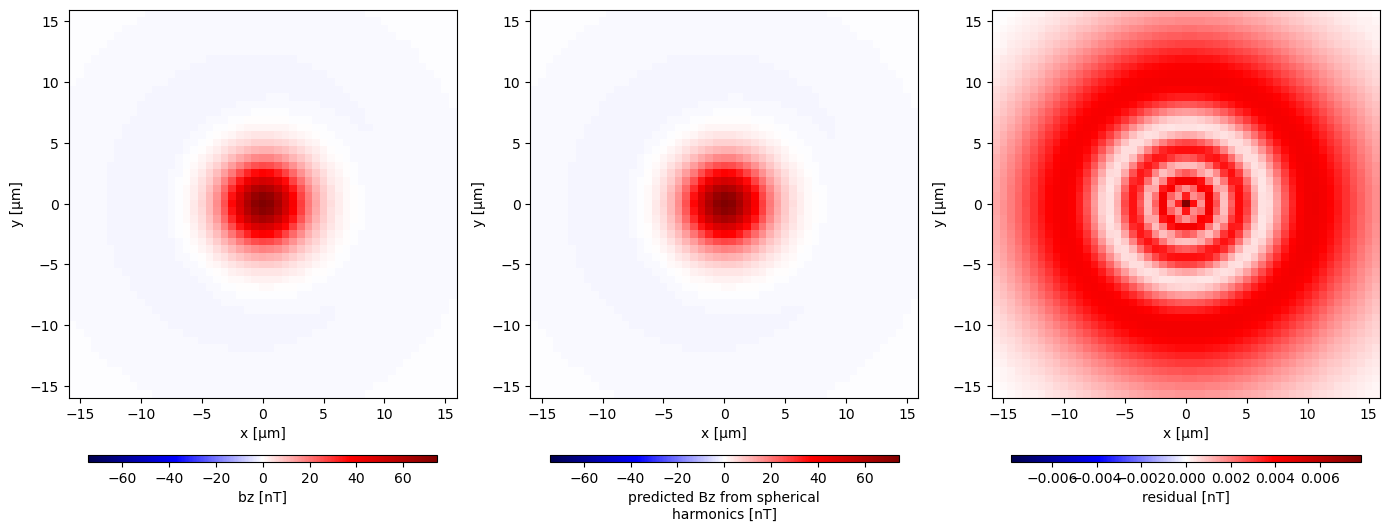

Processing model: eps12 at height 7.0 µm


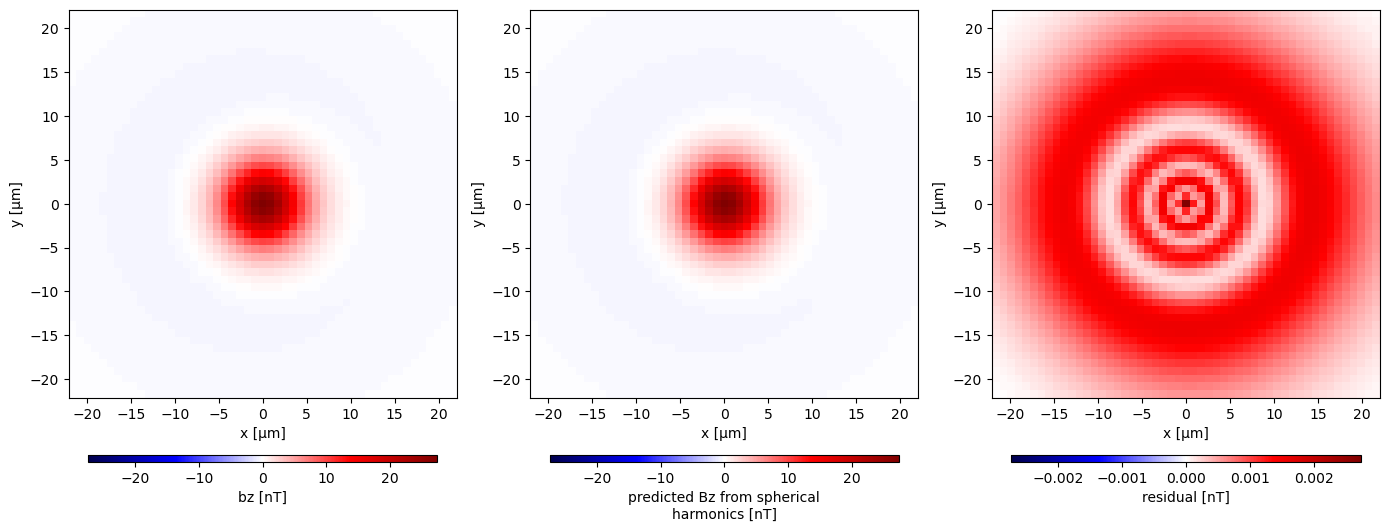

In [11]:
show_only = ["eps12"]
for file in grid_files:
    model_name = file.stem.split("_")[1]  # e.g., "eps3"
    height = float(file.stem.split("_")[2].replace("um", ""))

    if model_name not in show_only:
        continue  # skip sources

    print(f"Processing model: {model_name} at height {height} µm")

    # read .nc file 
    ds = xr.load_dataset(file)

    data = ds[['bz']].assign_coords(
        x=ds.x,
        y=ds.y,
        z=ds.z
    )

    data_table = vd.grid_to_table(data)
    coordinates = (data_table.x, data_table.y, data_table.z)

    location = ds.centroid.values
    sph = mt.SphericalHarmonicsBz(location, damping=1e-1, min_degree=1, max_degree=10).fit(coordinates, data.bz)
    sph.update_location(coordinates, data_table)

    #predic bz
    bz_pred = sph.predict(coordinates)

    data = data.assign(bz_sph=(["y", "x"], np.reshape(bz_pred, np.shape(data.bz))))
    data.bz_sph.attrs = {"long_name": "predicted Bz from spherical harmonics", "units": "nT"}

    residual = data.bz.values - data.bz_sph.values
    data = data.assign(residual_sph=(["y", "x"], residual))
    data.residual_sph.attrs = {"long_name": "residual", "units": "nT"}


    fig, axes = plt.subplots(1, 3, figsize=(14, 6))
    cbar_kwargs = dict(orientation="horizontal", aspect=50, pad=0.1, shrink=0.9)
    for field, ax in zip(["bz", "bz_sph", "residual_sph"], axes.ravel()):
        vmax = None
        vmin = None
        data[field].plot.pcolormesh(ax=ax, cmap="seismic", cbar_kwargs=cbar_kwargs, vmax=vmax, vmin=vmin)
    for ax in axes.ravel():
        ax.set_aspect("equal")
    plt.tight_layout()
    plt.show()

In [12]:
def angular_distance(vec_a, vec_b):
    dot_product = np.dot(vec_a, vec_b)
    
    magnitude_a = np.linalg.norm(vec_a)
    magnitude_b = np.linalg.norm(vec_b)
    
    cos_theta = dot_product / (magnitude_a * magnitude_b)

    theta = np.rad2deg(np.arccos(cos_theta))
    
    return theta

In [24]:
results = []

for file in grid_files:
    model_name = file.stem.split("_")[1]  # e.g., "eps3"
    height = float(file.stem.split("_")[2].replace("um", ""))

    # print(f"Processing model: {model_name} at height {height} µm")

    # read .nc file 
    ds = xr.load_dataset(file)

    micromag_moment = ds.magnetic_moment.values
    
    data = ds[['bz']].assign_coords(
        x=ds.x,
        y=ds.y,
        z=ds.z
    )

    data_table = vd.grid_to_table(data)
    coordinates = (data_table.x, data_table.y, data_table.z)

    location = ds.centroid.values
    sph = mt.SphericalHarmonicsBz(location, damping=1e-1, min_degree=1, max_degree=10).fit(coordinates, data.bz)
    sph.update_location(coordinates, data_table)

    spherical_moment = sph.magnetic_moment_

    amp = mg.vector_to_angles(micromag_moment)[2]
    eamp = mg.vector_to_angles(spherical_moment)[2]


    # angle misfit
    angle_misfit = angular_distance(micromag_moment, spherical_moment)
    
    # moment misfit
    m_misfit = abs(float((amp-eamp)/amp)*100)


    results.append({
        "model": model_name,
        "height": height,
        "angle_misfit": angle_misfit,
        "moment_misfit": m_misfit
    })


In [25]:
df = pd.DataFrame(results)
df

,model,height,angle_misfit,moment_misfit
0,eps0,0.050,0.002781,0.068179
1,eps0,0.075,0.003896,0.077816
2,eps0,0.100,0.004385,0.083031
3,eps0,0.150,0.002364,0.072751
4,eps0,0.200,0.004191,0.086589
...,...,...,...,...
355,eps9,2.000,0.087512,0.589983
356,eps9,3.000,0.065641,0.562485
357,eps9,4.000,0.052403,0.537528
358,eps9,5.000,0.043576,0.518629


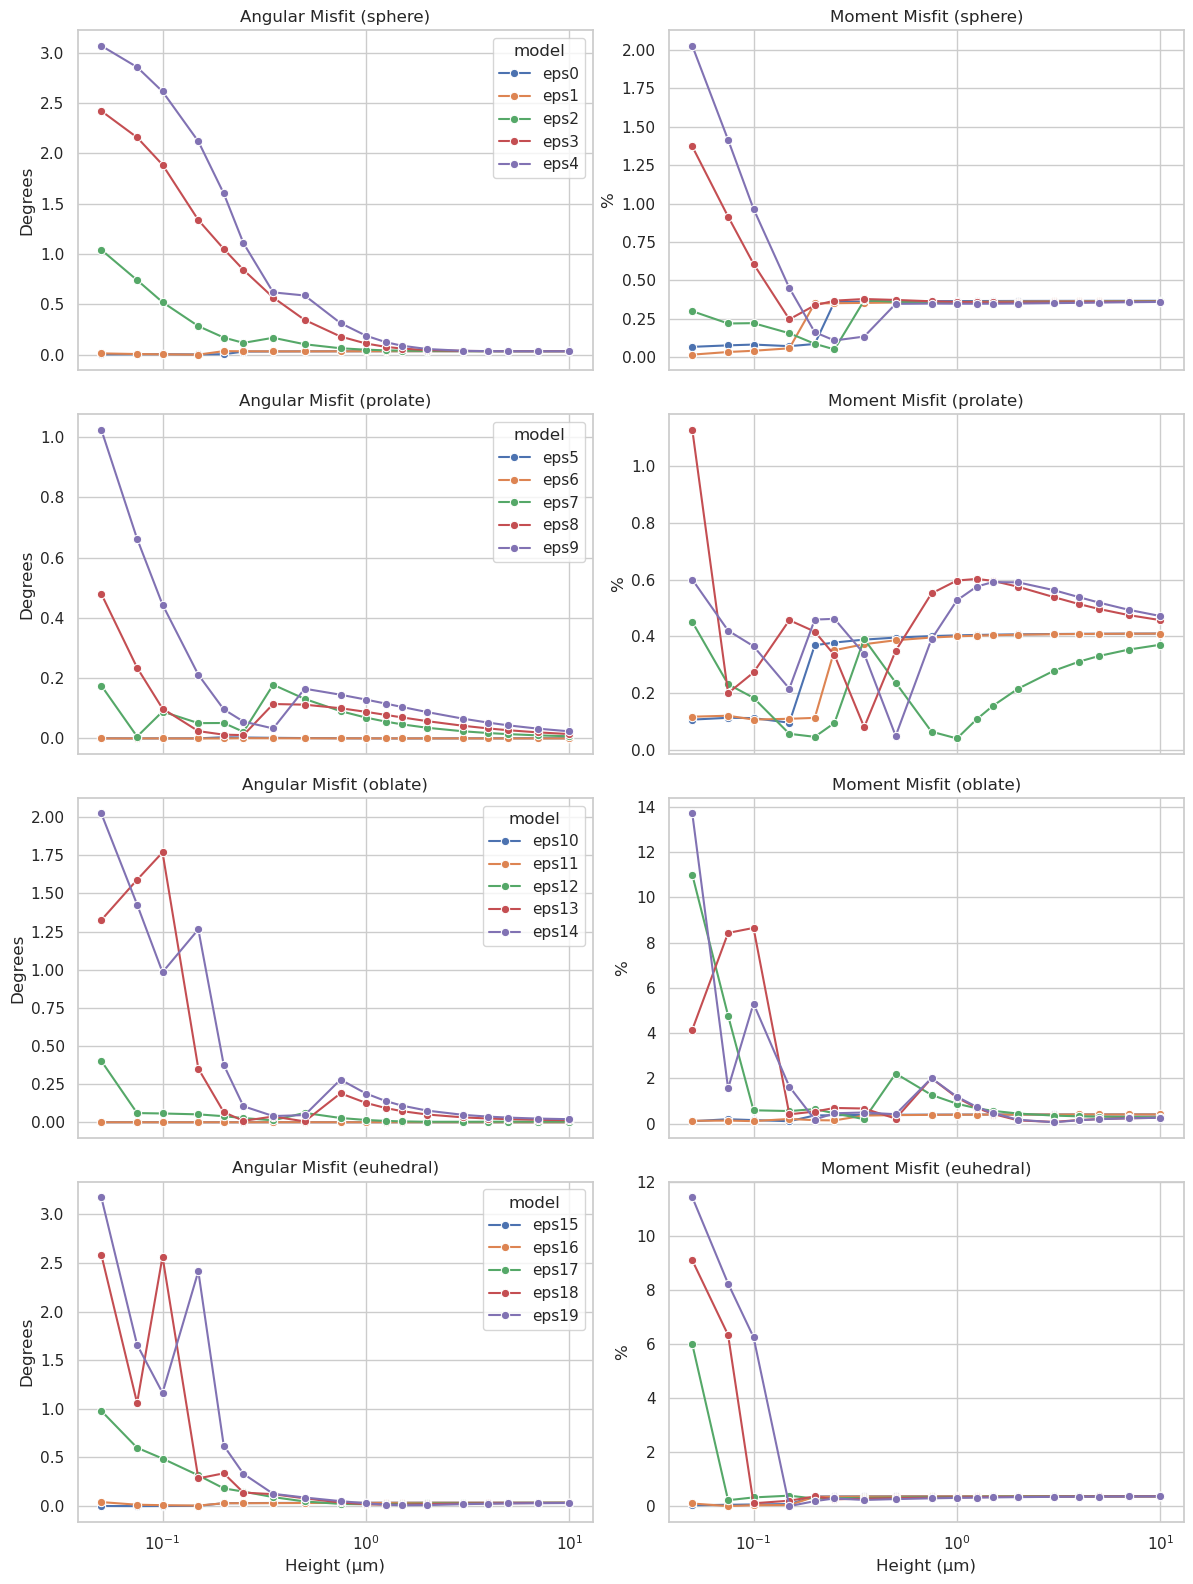

In [32]:
sns.set(style="whitegrid")

# --- extract model number (epsX → X)
df["model_num"] = df["model"].str.extract(r"(\d+)").astype(int)

# --- sort by model number
df = df.sort_values("model_num")

# --- create groups of 5 models
group_size = 5
df["group"] = df["model_num"] // group_size

groups = df["group"].unique()
n_groups = len(groups)

# --- create subplots (n rows, 2 columns)
fig, axes = plt.subplots(n_groups, 2, figsize=(12, 4 * n_groups), sharex=True)

# if there is only one group, axes is not 2D → fix shape
if n_groups == 1:
    axes = np.array([axes])

# --- loop over groups
particle_type = ['sphere', 'prolate', 'oblate', 'euhedral']
for i, g in enumerate(groups):
    df_g = df[df["group"] == g]

    # ANGLE MISFIT
    sns.lineplot(
        data=df_g,
        x="height",
        y="angle_misfit",
        hue="model",
        marker="o",
        ax=axes[i, 0]
    )
    axes[i, 0].set_title(f"Angular Misfit ({particle_type[i]})")
    axes[i, 0].set_ylabel("Degrees")
    axes[i, 0].set_xscale('log')

    # MOMENT MISFIT
    sns.lineplot(
        data=df_g,
        x="height",
        y="moment_misfit",
        hue="model",
        marker="o",
        ax=axes[i, 1],
        legend=False
    )
    axes[i, 1].set_title(f"Moment Misfit ({particle_type[i]})")
    axes[i, 1].set_ylabel("%")
    axes[i, 1].set_xscale('log')

# set common x-axis label only for bottom row
for ax in axes[-1, :]:
    ax.set_xlabel("Height (µm)")

plt.tight_layout()
plt.show()